# HanuAI ML Assessment — Task 2: Advanced EDA and Text Mining

This notebook analyzes the supplied `Hanuai_task2_assignment.csv` file. It includes schema/data-quality checks, descriptive EDA, narrative cleaning, rule-based issue tagging, TF-IDF + K-Means clustering, and export of an enriched dataset.

**Important:** issue tags and repair strategies are heuristic, exploratory labels—not verified engineering diagnoses. Counts are not failure rates without exposure denominators.

In [10]:
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

DATA_PATH = r"D:\hanuai-review-analysis\Task2\Hanuai_task2_assignment.csv"  # update if your file is elsewhere
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.astype(str).to_frame("dtype"))


Shape: (1000, 20)


,Event id,Opened date,CAUSAL_VERBATIM,CORRECTION_VERBATIM,CUSTOMER_VERBATIM,BUILD_DATE,BUILD_PLANT_DESC,CAUSAL_CD_DESC,COMPLAINT_CD_DESC,IN_USE_DATE,MAKE,MODEL,MODLYR,PLANT,Trigger,Failure Component,Failure Condition,Additional Context,Fix Component,Fix Condition
0,D-14801,9/17/2019,unable to duplicate the concern at this time r...,"waiting for techline engineering response, att...",Customer reports that radio and screen is inte...,2019-08-14T00:00:00.000Z,Flint,Module/Component-No/Incorrect Communication,Audio/Entertainment/Navigation - Other issues,2019-09-10T00:00:00.000Z,NovaSprint,AeroSpecter,2020,FLT,['No Additional Functionality'],"['Audio Unit', 'Display']","['Controls Irresponsive', 'Black Screen']",['No Additional Context'],"['Radio', 'SPS']","['Replaced', 'Programmed']"
1,D-14869,7/6/2020,upon inspection radio screen was found to be b...,and ground at radio as stated in service info ...,RADIO IS INOPERABLE CHECK AND ADVISE,2019-08-16T00:00:00.000Z,Fort Wayne,Module/Component-Shorted,Audio/Entertainment/Navigation - Other issues,2020-03-26T00:00:00.000Z,NebulaCruiser,StellarGlide,2020,FTW,['No Additional Functionality'],"['Radio', 'Display', 'Radio']","['Inoperative', 'Black Screen', 'No Sound']",['No Additional Context'],"['Radio', 'USB']","['Replaced', 'Programmed']"
2,D-14555,1/9/2020,Scanned found no codes checked for bulletins f...,radio module internal failure,CUSTOMER STATES RADIO SCREEN AND ONSTAR KEEPS ...,2019-08-06T00:00:00.000Z,Flint,Module/Component-Worn/Stripped,Audio/Entertainment/Navigation - Other issues,2019-11-29T00:00:00.000Z,ThunderVolt,HyperFury X,2020,FLT,['No Additional Functionality'],"['Display', 'OnStar', 'Radio Module']","['Inoperative', 'Inoperative', 'Internal Fault']",['No Additional Context'],['Radio'],['Replaced']
3,D-14704,4/14/2020,"PANTALLA SE PONE NEGRA, LO QUE PROVOCA QUE AL ...",DESPUES DE REALIZAR LA INPECCION VISUAL Y OPER...,PANTALLA SE PONE NEGRA,2019-08-12T00:00:00.000Z,Spring Hill - Truck,Module/Component-No/Incorrect Communication,Features/Controls/Displays - Other issues,2019-12-26T00:00:00.000Z,ThunderVolt,HyperFury X,2020,SHT,['When Reversing'],['Display'],['Black Screen'],['While Driving'],"['Radio', 'USB']","['Replaced', 'Programmed']"
4,D-15142,11/23/2020,INSPECTED VEHICLE AND CONFIRMED THAT THE...,SCRANNED FOR CODES NONE FOUND FOUND UPDATE N...,CUSTOMER STATES A MESSAGE OF LOST SATELITE SIG...,2019-08-27T00:00:00.000Z,Fort Wayne,Module/Component-Registers Incorrectly,Audio/Entertainment/Navigation - Other issues,2019-10-31T00:00:00.000Z,ThunderVolt,TurboFlare,2020,FTW,['No Additional Functionality'],['Radio'],['Malfunction'],['No Additional Context'],['Radio'],['Replaced']


,dtype
Event id,str
Opened date,str
CAUSAL_VERBATIM,str
CORRECTION_VERBATIM,str
CUSTOMER_VERBATIM,str
BUILD_DATE,str
BUILD_PLANT_DESC,str
CAUSAL_CD_DESC,str
COMPLAINT_CD_DESC,str
IN_USE_DATE,str


## 1. Data quality: missing values, duplicates, dates

In [11]:
print("Exact duplicate rows:", df.duplicated().sum())
if "Event id" in df:
    print("Duplicate Event id:", df["Event id"].duplicated().sum())
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))
for c in ["Opened date", "BUILD_DATE", "IN_USE_DATE"]:
    if c in df:
        df[c] = pd.to_datetime(df[c], errors="coerce", utc=(c != "Opened date"))
        if c != "Opened date":
            df[c] = df[c].dt.tz_convert(None)
print("Opened date range:", df["Opened date"].min(), "to", df["Opened date"].max())


Exact duplicate rows: 0
Duplicate Event id: 0


,missing_count
Fix Component,995
Fix Condition,995
Additional Context,995
Failure Condition,995
Trigger,995
Failure Component,995
CAUSAL_CD_DESC,3
CAUSAL_VERBATIM,1
IN_USE_DATE,1


Opened date range: 2019-08-27 00:00:00 to 2021-06-01 00:00:00


## 2. Clean text and parse list-like structured fields

In [12]:
text_cols = ["CAUSAL_VERBATIM", "CORRECTION_VERBATIM", "CUSTOMER_VERBATIM"]
for c in text_cols:
    df[c] = df[c].fillna("").astype(str).str.replace(r"\\s+", " ", regex=True).str.strip()

list_cols = ["Trigger", "Failure Component", "Failure Condition", "Additional Context", "Fix Component", "Fix Condition"]
def parse_listish(x):
    if pd.isna(x): return ""
    try:
        value = ast.literal_eval(str(x))
        if isinstance(value, list): return "; ".join(map(str, value))
    except Exception:
        pass
    return str(x).strip("[]' " + chr(34))

for c in list_cols:
    df[c + "_clean"] = df[c].map(parse_listish)

df["complaint_text"] = (df["CUSTOMER_VERBATIM"] + " " + df["CAUSAL_VERBATIM"] + " " + df["CORRECTION_VERBATIM"]).str.replace(r"\\s+", " ", regex=True).str.strip()
df["complaint_text_clean"] = df["complaint_text"].str.lower().str.replace(r"[^a-z0-9\\s-]", " ", regex=True).str.replace(r"\\s+", " ", regex=True).str.strip()
df["complaint_word_count"] = df["complaint_text_clean"].str.split().str.len()
display(df[["Event id", "complaint_word_count", "complaint_text_clean"]].head())


,Event id,complaint_word_count,complaint_text_clean
0,D-14801,360,customer reports that radio and screen is inte...
1,D-14869,340,radio is inoperable check and advise upon insp...
2,D-14555,325,customer states radio screen and onstar keeps ...
3,D-14704,339,pantalla se pone negra pantalla se pone negra ...
4,D-15142,289,customer states a message of lost satelite sig...


## 3. Descriptive EDA

\nTop values: CAUSAL_CD_DESC


,count
CAUSAL_CD_DESC,
Module/Component-No/Incorrect Communication,377
Module/Component-Shorted,237
Module/Component-Registers Incorrectly,121
Wiring/Electrical/Sensors-No/Incorrect Communication,50
Module/Component-Broken,41
Wiring/Electrical/Sensors-Shorted,23
Other-Campaign/ Tech Bulletin,22
Other-Follow operation,22
Other-No trouble found - adjusted / reprogrammed,21


\nTop values: COMPLAINT_CD_DESC


,count
COMPLAINT_CD_DESC,
Audio/Entertainment/Navigation - Audio,337
Audio/Entertainment/Navigation - Other issues,263
Audio/Entertainment/Navigation - Communication,194
Audio/Entertainment/Navigation - Video,103
Features/Controls/Displays - Other issues,47
Audio/Entertainment/Navigation - Navigation,32
Features/Controls/Displays - Gauges/Warning Lights,12
Audio/Entertainment/Navigation - Abnormal Noise,11
Features/Controls/Displays - Odometer,1


\nTop values: BUILD_PLANT_DESC


...

,count
MAKE,
ThunderVolt,488
NovaSprint,335
NebulaCruiser,125
TurboFlux,52


\nTop values: MODEL


,count
MODEL,
HyperFury X,148
TurboFlare,117
QuantumRider,109
AeroSpecter,86
NebulaJet,77
ElectroStreak,75
StellarGlide,62
ShadowPulse,61
FusionNova,59


\nTop values: MODLYR


,count
MODLYR,
2020,1000


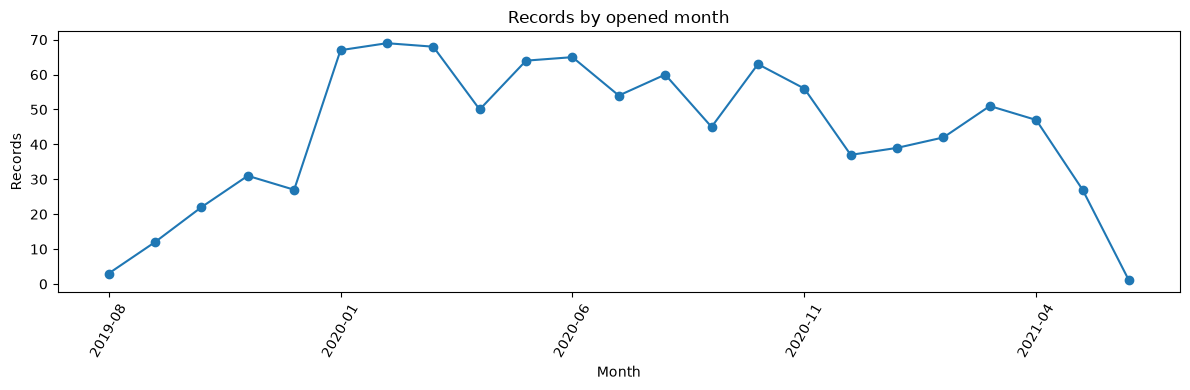

In [13]:
for col in ["CAUSAL_CD_DESC", "COMPLAINT_CD_DESC", "BUILD_PLANT_DESC", "MAKE", "MODEL", "MODLYR"]:
    print("\\nTop values:", col)
    display(df[col].value_counts(dropna=False).head(10).to_frame("count"))

df["Opened month"] = df["Opened date"].dt.to_period("M").astype(str)
monthly = df.groupby("Opened month").size()
monthly.plot(kind="line", figsize=(12,4), marker="o")
plt.title("Records by opened month")
plt.xlabel("Month")
plt.ylabel("Records")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


## 4. Rule-based issue tagging (multi-label baseline)

,tagged_records
issue_tags,
Software/update/programming,474
USB/SD/navigation,363
Audio/radio inoperative,330
Display/black screen,241
Electrical/wiring,165
Connectivity/integration,149
Other/unclear,142
Communication/network,119


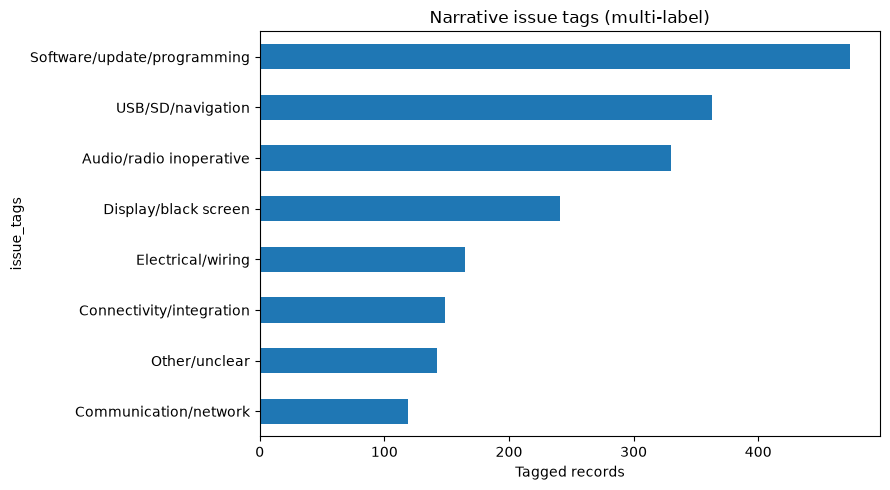

In [20]:
def classify_issue(s):
    t = (s or "").lower()
    tags = []
    rules = {
        "Display/black screen": ["black screen", "blank screen", "display", "screen goes black", "screen went black", "no display"],
        "Audio/radio inoperative": ["no sound", "audio", "mute", "radio will not play", "radio not working", "radio inop", "inop"],
        "Communication/network": ["lost communication", "ethernet bus", "no communication", "data line", "communication with radio"],
        "Software/update/programming": ["software", "update", "programming", "reprogram", "calibration", "failed update"],
        "USB/SD/navigation": ["usb", "sd card", "card reader", "navigation", "maps will not", "map data"],
        "Connectivity/integration": ["wifi", "wi-fi", "hotspot", "onstar", "bluetooth", "android auto", "carplay", "phone"],
        "Electrical/wiring": ["wire", "wiring", "connector", "terminal", "harness", "ground circuit", "power circuit"]
    }
    for tag, keywords in rules.items():
        if any(k in t for k in keywords): tags.append(tag)
    return "; ".join(tags or ["Other/unclear"])

df["issue_tags"] = df["complaint_text"].map(classify_issue)
tag_counts = df["issue_tags"].str.split("; ").explode().value_counts()
display(tag_counts.to_frame("tagged_records"))
tag_counts.sort_values().plot(kind="barh", figsize=(9,5))
plt.title("Narrative issue tags (multi-label)")
plt.xlabel("Tagged records")
plt.tight_layout()
import os
from pathlib import Path

REPORTS_DIR = Path(r"D:\hanuai-review-analysis\Task2\reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(REPORTS_DIR / "hanuai_issue_tags.png", dpi=300)
plt.show()


In [15]:
import os
print("Notebook working directory:", os.getcwd())
print("Reports folder path:", os.path.abspath("reports"))
print("Chart exists:", os.path.exists("reports/hanuai_issue_tags.png"))

Notebook working directory: d:\hanuai-review-analysis\Task2
Reports folder path: d:\hanuai-review-analysis\Task2\reports
Chart exists: True


## 5. Inferred repair strategy (heuristic)

In [16]:
def fix_category(s):
    t = (s or "").lower()
    if any(k in t for k in ["replaced", "replace", "new radio", "radio assembly"]): return "Component replacement"
    if any(k in t for k in ["programmed", "programming", "software update", "reprogram"]): return "Programming/software"
    if any(k in t for k in ["wire", "connector", "terminal", "harness", "circuit"]): return "Wiring/connector repair"
    if any(k in t for k in ["reset", "global reset", "factory reset"]): return "Reset/reinitialization"
    if any(k in t for k in ["unable to duplicate", "no problem found", "unable to verify"]): return "Unable to reproduce/monitor"
    return "Other/unclear"

df["fix_strategy"] = (df["CORRECTION_VERBATIM"].fillna("") + " " + df["CAUSAL_VERBATIM"].fillna("")).map(fix_category)
display(df["fix_strategy"].value_counts().to_frame("count"))


,count
fix_strategy,
Component replacement,889
Programming/software,47
Other/unclear,46
Wiring/connector repair,14
Reset/reinitialization,3
Unable to reproduce/monitor,1


## 6. TF-IDF + K-Means clustering

In [17]:
vectorizer = TfidfVectorizer(stop_words="english", max_features=2500, ngram_range=(1,2), min_df=3, max_df=0.90)
X = vectorizer.fit_transform(df["complaint_text_clean"].fillna(""))
k = 5  # experiment with 3, 4, 5, 6 and compare interpretability
km = KMeans(n_clusters=k, random_state=42, n_init=10)
df["text_cluster"] = km.fit_predict(X)
terms = np.array(vectorizer.get_feature_names_out())
for i in range(k):
    center = km.cluster_centers_[i]
    print(f"Cluster {i} (n={(df['text_cluster'] == i).sum()}):", ", ".join(terms[center.argsort()[::-1][:12]]))
display(df["text_cluster"].value_counts().sort_index().to_frame("records"))


Cluster 0 (n=98): camera, rear, coax, camera inop, cable, video, backup, backup camera, view, inop, replaced, screen
Cluster 1 (n=47): card, sd, sd card, error, navigation, error code, nav, message, usb, replaced, code, tac
Cluster 2 (n=300): screen, blank, radio screen, display, ok, replaced, ground, communication, power, internal, tested, checked
Cluster 3 (n=213): code, update, usb, module, fault, internal, claim, internal fault, radio module, replaced, performed, replaced radio
Cluster 4 (n=342): xm, tac, customer, vehicle, replace, replaced, states, customer states, case, replace radio, concern, replaced radio


,records
text_cluster,
0,98
1,47
2,300
3,213
4,342


## 7. Export enriched dataset

In [18]:
import os

output_path = r"D:\hanuai-review-analysis\Task2\HanuAI_Task2_Analyzed_Dataset.csv"
os.makedirs(os.path.dirname(output_path), exist_ok=True)

df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("File exists:", os.path.exists(output_path))
print("Dataset shape:", df.shape)

Saved: D:\hanuai-review-analysis\Task2\HanuAI_Task2_Analyzed_Dataset.csv
File exists: True
Dataset shape: (1000, 33)
